0. 필요한 모듈 불러오기

In [28]:
# 데이터 로드, 시각화
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 분할, 교차검증, 튜닝
from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV
    )

# 전처리
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# 특성 추출 및 결합
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion

# 리샘플러 및 파이프라인 - SMOTE, NearMiss
from imblearn.over_sampling import SMOTE        # SMOTE (Over)
from imblearn.under_sampling import NearMiss    # NearMiss (Under)
from imblearn.pipeline import Pipeline

# 모델
from sklearn.linear_model\
    import LogisticRegression       # LR
from sklearn.tree\
    import DecisionTreeClassifier   # DT
from sklearn.ensemble import (
    RandomForestClassifier,         # RF
    ExtraTreesClassifier,           # ET
)
from lightgbm import LGBMClassifier # LGB
from xgboost import XGBClassifier   # XGB

# 평가 지표
from sklearn.metrics import (
    average_precision_score,    # AP
    roc_auc_score,              # AUROC
    precision_recall_curve,     # PR
    f1_score,                   # F1
    fbeta_score,                # F-beta
    matthews_corrcoef,          # MCC
    precision_score,            # Precision
    recall_score,               # Recall
    brier_score_loss,           # Brier
)

# 평가 시각화
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)
from sklearn.calibration import CalibrationDisplay

# 공통 설정
SEED = 33

1. 데이터 로드

In [61]:
data = pd.read_csv("givemesomecredit.csv")

short_names = {
    'SeriousDlqin2yrs': 'Dlq2yrs',
    'RevolvingUtilizationOfUnsecuredLines': 'RevUtil',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'PastDue_30-59',
    'DebtRatio': 'DebtRatio',
    'MonthlyIncome': 'Income',
    'NumberOfDependents': 'Dependents',
    'CombinedDefaulted': 'CombDefault',
    'CombinedCreditLoans': 'CombCredit'
}

TARGET = "Dlq2yrs"

data = data.rename(columns=short_names)

X = data.drop(columns=[TARGET])
y = data[TARGET]

data.head(5)

,Dlq2yrs,RevUtil,Age,PastDue_30-59,DebtRatio,Income,Dependents,CombDefault,CombCredit
0,1,0.766127,45,2,0.802982,9120,2,1,1
1,0,0.957151,40,0,0.121876,2600,1,0,0
2,0,0.658180,38,1,0.085113,3042,0,1,0
3,0,0.233810,30,0,0.036050,3300,0,0,0
4,0,0.907239,49,1,0.024926,63588,0,1,1


- <b>[Target]</b>
    - Dlq2yrs: 신청자가 90일 이상의 연체(채무불이행) 또는 그보다 심각한 상황을 경험했는지 여부 - N (연체 없음 = 0) / Y (연체 있음 = 1) - 이진 범주형
- <b>[Feature]</b>
    - RevUtil: 신용카드 및 개인 신용한도(마이너스 통장 등)의 총 잔액 비율(한도 소진율) - 백분율 (연속형)
    - Age: 신청자 연령(세) - 정수형
    - PastDue_30-59: 최근 2년 간 30~59일 연체 발생 횟수 - 정수형
    - DebtRatio: 월간 총소득 대비 월간 부채 상환액, 위자료, 생활비의 비율(부채비율) - 수치형
    - Income: 월 소득 - 실수형
    - Dependents: 본인 제외 부양가족 수 - 범주형
    - CombDefault: 30~89일 또는 90일 이상 연체한 횟수 - 범주형
    - CombCredit: 부동산 담보 대출 및 주택자산 신용한도(HELOC)를 포함한 개설된 대출 및 신용한도의 총 개수 - 범주형

2. 데이터 분할 - stratify=y로 Train/Test 분리 및 Test 격리, 분할 인덱스 저장

In [4]:
TEST_SIZE = 0.2

X_train, X_test, y_train, y_test = train_test_split (
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=SEED,
)

np.savez(
    "split_indices.npz",
    train_idx = X_train.index.to_numpy(),
    test_idx = X_test.index.to_numpy(),
)

3. Train 데이터 시각화 및 실험 기준 설정 - 주 지표 AP, threshold 목적 사전 설정

In [5]:
# Feature - 기초통계, 왜도, 결측치 확인
overview = pd.concat (
    [
        X_train.describe().T,
        X_train.skew().rename("skew"),
        X_train.isnull().sum().rename("isnull")
    ],
    axis=1
    )
overview

,count,mean,std,min,25%,50%,75%,max,skew,isnull
RevUtil,120000.0,6.008512,249.011519,0.0,0.029851,0.154467,0.559169,50708.0,103.498422,0
Age,120000.0,52.328342,14.789786,21.0,41.000000,52.000000,63.000000,109.0,0.189488,0
PastDue_30-59,120000.0,0.413508,4.104862,0.0,0.000000,0.000000,0.000000,98.0,23.056155,0
DebtRatio,120000.0,356.018387,2206.085343,0.0,0.174629,0.366719,0.870754,329664.0,93.458696,0
Income,120000.0,6670.639008,12779.028666,0.0,3900.000000,6600.000000,7379.000000,3008750.0,136.857663,0
Dependents,120000.0,0.736475,1.105007,0.0,0.000000,0.000000,1.000000,20.0,1.618072,0
CombDefault,120000.0,0.202083,0.401556,0.0,0.000000,0.000000,0.000000,1.0,1.483837,0
CombCredit,120000.0,0.741283,0.437931,0.0,0.000000,1.000000,1.000000,1.0,-1.101941,0


Result => 결측치 없음. RevUtil, DebtRatio, Income 에서 강한 왜도, PastDue_30-59에서 어느정도의 왜도가 보임

In [6]:
# 연체 특수값 빈도
print(X_train["PastDue_30-59"].value_counts().sort_index())
print("96, 98에 대한 처리 필요")

# 로그 변환 대상의 범위·극단값 확인
log_cols = ["RevUtil", "DebtRatio", "Income"]

X_train[log_cols].quantile(
    [0, 0.5, 0.95, 0.99, 0.999, 1]
).T

PastDue_30-59
0     100831
1      12813
2       3702
3       1382
4        589
5        284
6        112
7         43
8         23
9         10
10         3
12         1
13         1
96         4
98       202
Name: count, dtype: int64
96, 98에 대한 처리 필요


,0.000,0.500,0.950,0.990,0.999,1.000
RevUtil,0.0,0.154467,1.00,1.091738,1620.009,50708.0
DebtRatio,0.0,0.366719,2451.05,4993.000000,10613.074,329664.0
Income,0.0,6600.000000,13500.00,23333.000000,71950.050,3008750.0


In [32]:
# Target - 클래스 불균형 확인
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
ir = round((neg/pos), 4)
print(f"IR = {ir}")

IR = 13.9607


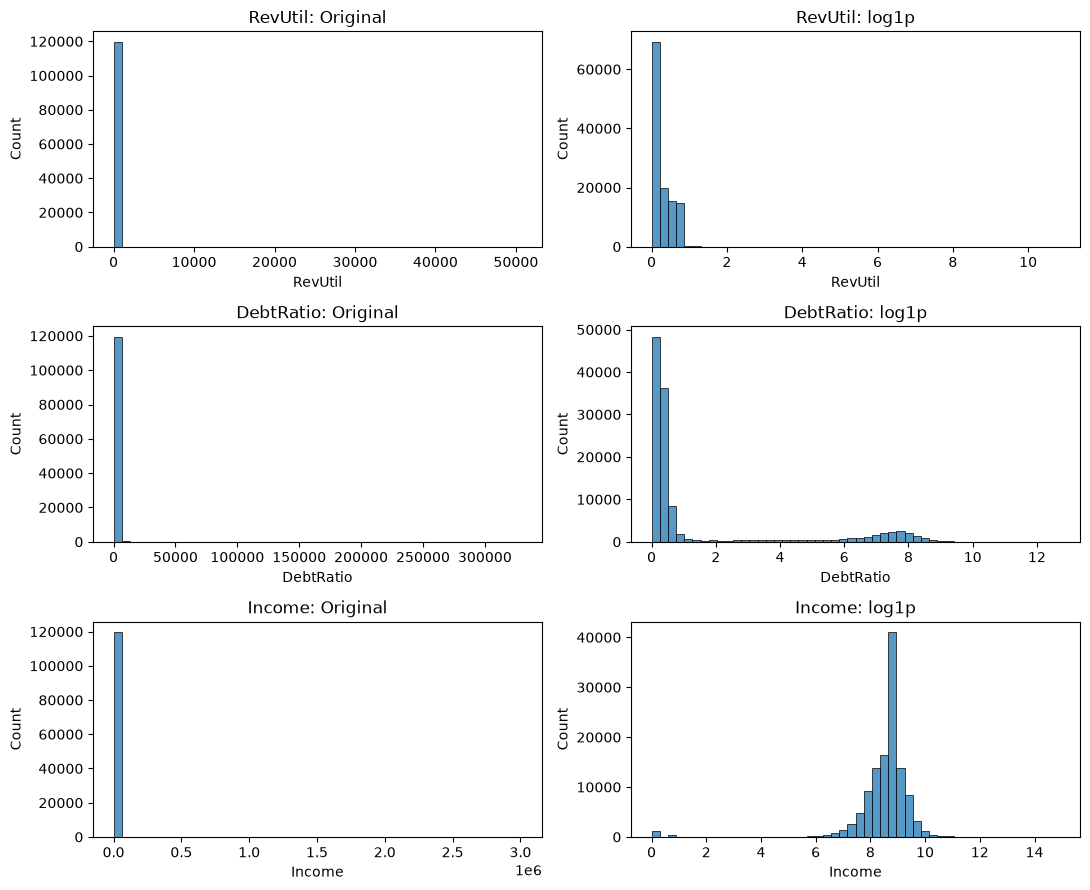

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9))

for i, col in enumerate(log_cols):
    sns.histplot(
        X_train[col], bins=50, ax=axes[i, 0]
    )
    sns.histplot(
        np.log1p(X_train[col]), bins=50, ax=axes[i, 1]
    )

    axes[i, 0].set_title(f"{col}: Original")
    axes[i, 1].set_title(f"{col}: log1p")

plt.tight_layout()
plt.show()

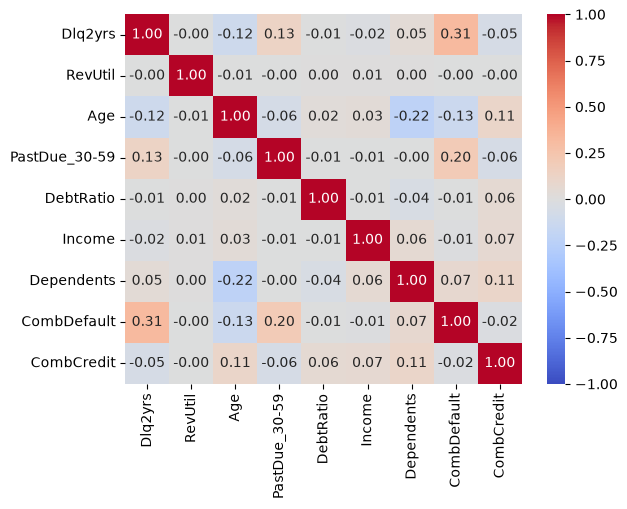

In [57]:
corr = data.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

# 4. 결측치·왜도·특수값 확인/처리 - 유효한 위험 신호인지 확인 후 처리 후보 비교 - cv 내 구성

In [25]:
# 전처리기: 처리 규칙을 한 객체로 묶어 Pipeline과 CV에서 재사용한다.
# BaseEstimator: 설정 조회·변경 및 CV에서 객체 복제를 지원한다.
# TransformerMixin: fit 후 transform을 호출하는 fit_transform 등을 제공한다.
class GMSCPreprocessor(BaseEstimator, TransformerMixin):
    # 생성할 때는 설정만 저장한다. 중앙값 계산은 fit에서 수행한다.
    def __init__(self, use_log=True):
        # True면 로그 변환 적용, False면 특수값 처리만 수행한다.
        self.use_log = use_log

    # fit: 현재 fold의 학습 데이터에서 변환에 필요한 값을 구해 저장한다.
    # y는 Pipeline 호환용 인자이며 이 전처리에서는 정답을 사용하지 않는다.
    def fit(self, X, y=None):
        col = "PastDue_30-59"
        # isin은 96 또는 98인 행을 True로 표시하고, ~는 True/False를 뒤집는다.
        # 따라서 normal은 특수값이 아닌 행을 선택하는 마스크다.
        normal = ~X[col].isin([96, 98])
        # loc[행 조건, 컬럼]으로 정상값만 선택해 중앙값을 구한다.
        # 이름 끝의 _는 fit에서 학습한 속성이라는 sklearn 관례다.
        self.pastdue_median_ = X.loc[normal, col].median()
        # 데이터를 반환하는 것이 아니라 학습을 마친 객체 자신을 반환한다.
        return self

    # transform: 새 통계를 계산하지 않고 fit에서 저장한 규칙으로 데이터를 변환한다.
    # 학습·검증 데이터에 같은 규칙을 적용하므로 검증 데이터의 정보가 새지 않는다.
    def transform(self, X):
        # 원본 DataFrame을 덮어쓰지 않도록 복사본에서 작업한다.
        result = X.copy()
        col = "PastDue_30-59"
        special = result[col].isin([96, 98])

        # 치환 전에 특수값 여부를 별도 특성으로 보존한다(True=1, False=0).
        result["PastDue_special_flag"] = special.astype(int)
        # 특수값이 있는 행만 학습 데이터에서 구한 중앙값으로 바꾼다.
        result.loc[special, col] = self.pastdue_median_

        if self.use_log:
            cols = ["RevUtil", "DebtRatio", "Income"]
            # log1p(x)=log(1+x): 0도 처리할 수 있고 큰 값 사이의 간격을 줄인다.
            # 현재 EDA에서 이 세 컬럼의 최솟값은 0이다. 왜도가 완전히 사라지는 것은 아니다.
            result[cols] = np.log1p(result[cols])

        # 컬럼명과 행 인덱스를 유지한 변환 결과를 반환한다.
        return result

# 5. 모델 비교 및 AP/AUROC 기반 최적 모델 선발

In [33]:
# Model 및 Scoring 세트 구성 및 모델 테스트 폴드 구성
models = {
    # Logistic Regression
    "LR": LogisticRegression(
        max_iter=2000,
        random_state=SEED,
    ),
    # Decision Tree         
    "DT": DecisionTreeClassifier(
        random_state=SEED,
    ),
    # Random Forest
    "RF": RandomForestClassifier(
        n_estimators=100,
        random_state=SEED,
        n_jobs=1,
    ),
    # Extra Tree
    "ET": ExtraTreesClassifier(
        n_estimators=100,
        random_state=SEED,
        n_jobs=1,
    ),
    # LightGBM
    "LGB": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=SEED,
        n_jobs=1,
        verbosity=-1,
    ),
    # eXtreme Gradient Boosting
    "XGB": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=1,
    ),
}

scoring = {
    "AP": "average_precision",
    "AUROC": "roc_auc"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

cv_splits = list(cv.split(X_train, y_train))

In [38]:
# Model Test
summaty_rows, fold_rows = [], []

for name, model in models.items():
    print(f"{name} 평가 시작...", flush=True)

    pipe = Pipeline([
        ("clean", GMSCPreprocessor(use_log=True)),
        ("scale", StandardScaler()),
        ("model", clone(model)),
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=3,
        error_score="raise",
    )

    for i in range(len(cv_splits)):
        fold_rows.append({
            "model": name,
            "fold": i + 1,
            "AP": scores["test_AP"][i],
            "AUROC": scores["test_AUROC"][i],
            "fit_time_sec": scores["fit_time"][i],
        })

    summaty_rows.append({
        "model": name,
        "AP_mean": scores["test_AP"].mean(),
        "AP_std": scores["test_AP"].std(ddof=1),
        "AUROC_mean": scores["test_AUROC"].mean(),
        "AUROC_std": scores["test_AUROC"].std(ddof=1),
        "fit_time_mean_sec": scores["fit_time"].mean(),
    })

    results = pd.DataFrame(summaty_rows).sort_values(
        "AP_mean", ascending=False
    )
    results.to_csv("baseline_summary.csv", index=False)
    pd.DataFrame(fold_rows).to_csv("baseline_folds.csv", index=False)

    print(
        f"{name} 평가 완료: "
        f"AP = {scores['test_AP'].mean():.3f}, "
        f"AUROC = {scores['test_AUROC'].mean():.3f} ",
        flush=True,
    )

LR 평가 시작...
LR 평가 완료: AP = 0.277, AUROC = 0.823 
DT 평가 시작...
DT 평가 완료: AP = 0.111, AUROC = 0.599 
RF 평가 시작...
RF 평가 완료: AP = 0.300, AUROC = 0.825 
ET 평가 시작...
ET 평가 완료: AP = 0.272, AUROC = 0.811 
LGB 평가 시작...
LGB 평가 완료: AP = 0.341, AUROC = 0.851 
XGB 평가 시작...
XGB 평가 완료: AP = 0.350, AUROC = 0.855 


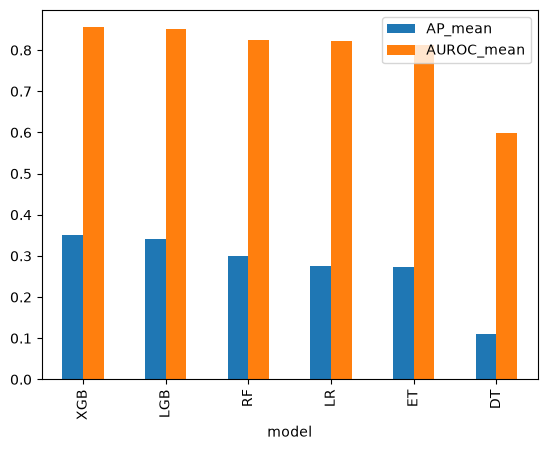

In [67]:
results.set_index("model")[["AP_mean", "AUROC_mean"]].plot(kind='bar')
plt.show()

Result =>  
- 1. XGB    -> 선별
- 2. LGB    -> 선별
- 3. RF     -> 선별
- 4. LR     -> 선별
- 5. ET
- 6. DT

In [56]:
selected_model = {}
selected_model["XGB"] = models["XGB"]
selected_model["LGB"] = models["LGB"]
selected_model["LR"] = models["LR"]
selected_model["RF"] = models["RF"]
print(selected_model.keys())

dict_keys(['XGB', 'LGB', 'LR', 'RF'])


# 6. 피처 엔지니어링 - 원본 / 원본 + 도메인 파생변수 / 스케일링 + PCA
-> 도메인 파생변수의 기여 시각화를 위해 Feature Importance 그래프로 특성 선택의 근거 제시

In [64]:
feature_options = {
    "Original": "passthrough",
    "PCA": PCA(n_components=0.95, svd_solver="full"),
}

feature_fold_rows = []

for model_name, base_model in selected_model.items():
    for feature_name, feature_step in feature_options.items():
        print(f"{model_name} / {feature_name} 평가 시작...", flush=True)

        model = clone(base_model)

        # 불균형 보정 없음
        if model_name in ("XGB", "LGB"):
            model.set_params(scale_pos_weight=1.0)
        if "class_weight" in model.get_params():
            model.set_params(class_weight=None)

        # PCA 조건별 객체 생성
        feature_transformer = (
            clone(feature_step)
            if feature_name == "PCA"
            else "passthrough"
        )

        pipe = Pipeline([
            ("clean", GMSCPreprocessor()),
            ("scale", StandardScaler()),
            ("feature", feature_transformer),
            ("model", model),
        ])

        # 기존 모델 비교와 같은 학습/분할
        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv_splits,
            scoring=scoring,
            return_estimator=True,
            n_jobs=3,
            error_score="raise",
        )

        for i, fitted_pipe in enumerate(scores["estimator"]):
            if feature_name == "PCA":
                n_features = (
                    fitted_pipe.named_steps["feature"].n_components_
                )
            else:
                n_features = (
                    fitted_pipe.named_steps["scale"].n_features_in_
                )

            feature_fold_rows.append({
                "model": model_name,
                "feature": feature_name,
                "fold": i + 1,
                "n_features": int(n_features),
                "AP": scores["test_AP"][i],
                "AUROC": scores["test_AUROC"][i],
                "fit_time_sec": scores["fit_time"][i],
            })

        # 조건 하나가 끝날 때마다 fold별 결과 저장
        pd.DataFrame(feature_fold_rows).to_csv(
            "feature_folds.csv", index=False
        )

        print(
            f"완료: AP={scores['test_AP'].mean():.4f}, "
            f"AUROC={scores['test_AUROC'].mean():.4f}",
            flush=True,
        )

XGB / Original 평가 시작...
완료: AP=0.3498, AUROC=0.8553
XGB / PCA 평가 시작...
완료: AP=0.3366, AUROC=0.8483
LGB / Original 평가 시작...
완료: AP=0.3405, AUROC=0.8510
LGB / PCA 평가 시작...
완료: AP=0.3318, AUROC=0.8456
LR / Original 평가 시작...
완료: AP=0.2767, AUROC=0.8228
LR / PCA 평가 시작...
완료: AP=0.2698, AUROC=0.8168
RF / Original 평가 시작...
완료: AP=0.2996, AUROC=0.8246
RF / PCA 평가 시작...
완료: AP=0.2892, AUROC=0.8190


In [65]:
feature_folds = pd.DataFrame(feature_fold_rows)

feature_summary = (
    feature_folds
    .groupby(["model", "feature"], sort=False)
    .agg(
        AP_mean=("AP", "mean"),
        AP_std=("AP", "std"),
        AUROC_mean=("AUROC", "mean"),
        AUROC_std=("AUROC", "std"),
        n_features_mean=("n_features", "mean"),
        fit_time_mean_sec=("fit_time_sec", "mean"),
    )
    .reset_index()
    .sort_values(
        ["model", "AP_mean"],
        ascending=[True, False],
        kind="stable",
    )
)

feature_summary.to_csv("feature_summary.csv", index=False)

display(feature_summary)

# 모델별로 AP가 높은 피처 조건 확인
best_feature_per_model = (
    feature_summary.groupby("model", sort=False).head(1)
)
display(best_feature_per_model)

,model,feature,AP_mean,AP_std,AUROC_mean,AUROC_std,n_features_mean,fit_time_mean_sec
2,LGB,Original,0.340543,0.010282,0.851041,0.003277,9.0,0.988968
3,LGB,PCA,0.331763,0.017104,0.845551,0.003033,8.0,1.058474
4,LR,Original,0.276665,0.007002,0.822787,0.002976,9.0,0.197447
5,LR,PCA,0.269846,0.006086,0.816834,0.002921,8.0,0.214845
6,RF,Original,0.299616,0.010842,0.824629,0.006010,9.0,17.964974
7,RF,PCA,0.289204,0.009448,0.819008,0.001221,8.0,33.483334
0,XGB,Original,0.349816,0.013607,0.855252,0.003205,9.0,1.089375
1,XGB,PCA,0.336567,0.015977,0.848265,0.002976,8.0,1.192106


,model,feature,AP_mean,AP_std,AUROC_mean,AUROC_std,n_features_mean,fit_time_mean_sec
2,LGB,Original,0.340543,0.010282,0.851041,0.003277,9.0,0.988968
4,LR,Original,0.276665,0.007002,0.822787,0.002976,9.0,0.197447
6,RF,Original,0.299616,0.010842,0.824629,0.006010,9.0,17.964974
0,XGB,Original,0.349816,0.013607,0.855252,0.003205,9.0,1.089375


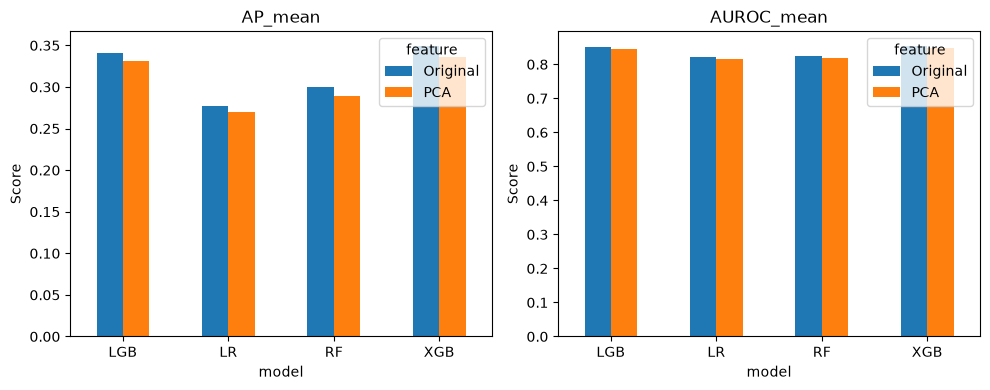

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["AP_mean", "AUROC_mean"]):
    feature_summary.pivot(
        index="model",
        columns="feature",
        values=metric,
    ).plot(kind="bar", ax=ax, rot=0, figsize=(10, 4))

    ax.set_title(metric)
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

## Result
PCA 적용 시 입력 차원은 9개에서 8개로 감소했으나, 비교한 4개 모델 전부 예측 성능은 하락했다. 제한적인 차원 축소에 비해 예측에 유용한 정보가 손실되었을 수 있고, 특히 트리 모델에서는 주성분 변환으로 원본 변수의 구조 활용이 어려워졌을 수 있다.

7. 리샘플링 - 없음 / scale_pos_weight(IR) / SMOTE / NearMiss 비교

----------- 각 cv fold 내에서만 fit, 동일한 cv 분할 -----------








----------- 모델 학습·튜닝까지 CV 내부에서 수행 -----------

9. 평가 지표 - AP(주 지표), AUROC / F1, F2, MCC, Precision, Recall / Brier(확률 예측 오차)
10. Threshold 결정 - 선택한 설정의 Train OOF 예측에서 F2 최대화, Test 사용 금지
11. 최종 재학습·Test 평가·성능 차이 분석 - 사전 지정 모델 간 paired bootstrap 신뢰구간
12. XAI 분석 - 최종 모델에 맞는 SHAP explainer 사용